<a href="https://colab.research.google.com/github/hashini5124-bit/World-energy-consumption/blob/main/Yet_another_copy_of_World_Energy_Forecasting_Product.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023.csv


In [ ]:
import pandas as pd
import numpy as np

filename = next(iter(uploaded.keys()))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (111, 60)

Column names:
['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68


In [ ]:
# Remove completely empty rows and columns
df = df.dropna(how="all").dropna(axis=1, how="all")

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Convert year columns from wide format to long format
year_columns = [
    col for col in df.columns
    if col.isdigit() and 1900 <= int(col) <= 2100
]

energy_df = df.melt(
    id_vars=["Country"],
    value_vars=year_columns,
    var_name="Year",
    value_name="Energy_Consumption"
)

# Clean and convert values
energy_df["Year"] = pd.to_numeric(energy_df["Year"], errors="coerce")
energy_df["Energy_Consumption"] = pd.to_numeric(
    energy_df["Energy_Consumption"], errors="coerce"
)

energy_df = energy_df.dropna(
    subset=["Country", "Year", "Energy_Consumption"]
)

energy_df = energy_df.sort_values(["Country", "Year"]).reset_index(drop=True)

print("Converted dataset shape:", energy_df.shape)
print("\nAvailable countries:")
print(energy_df["Country"].unique()[:20])

display(energy_df.head(10))

Converted dataset shape: (5728, 3)

Available countries:
['                 European Union #' '                 Non-OECD' 'Algeria'
 'Argentina' 'Australia' 'Austria' 'Azerbaijan' 'Bangladesh' 'Belarus'
 'Belgium' 'Brazil' 'Bulgaria' 'Canada' 'Central America' 'Chile' 'China'
 'China Hong Kong SAR' 'Colombia' 'Croatia' 'Cyprus']


,Country,Year,Energy_Consumption
0,European Union #,1965,34.03
1,European Union #,1966,35.19
2,European Union #,1967,36.41
3,European Union #,1968,38.98
4,European Union #,1969,42.20
5,European Union #,1970,45.28
6,European Union #,1971,46.70
7,European Union #,1972,49.20
8,European Union #,1973,52.01
9,European Union #,1974,51.50


In [ ]:
country_name = "India"

country_df = energy_df[
    energy_df["Country"].str.strip().str.lower() == country_name.lower()
].copy()

country_df = country_df.sort_values("Year").reset_index(drop=True)

print("Selected Country:", country_name)
print("Total records:", len(country_df))
print("Year range:",
      int(country_df["Year"].min()),
      "to",
      int(country_df["Year"].max()))

display(country_df.head())
display(country_df.tail())

Selected Country: India
Total records: 59
Year range: 1965 to 2023


,Country,Year,Energy_Consumption
0,India,1965,2.23
1,India,1966,2.30
2,India,1967,2.37
3,India,1968,2.53
4,India,1969,2.81


,Country,Year,Energy_Consumption
54,India,2019,33.54
55,India,2020,31.78
56,India,2021,34.51
57,India,2022,36.37
58,India,2023,39.02


In [ ]:
split_index = len(country_df) // 2

train_df = country_df.iloc[:split_index].copy()
test_df = country_df.iloc[split_index:].copy()

print("Total records:", len(country_df))
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining years:",
      int(train_df["Year"].min()), "to",
      int(train_df["Year"].max()))

print("Testing years:",
      int(test_df["Year"].min()), "to",
      int(test_df["Year"].max()))

Total records: 59
Training records: 29
Testing records: 30

Training years: 1965 to 1993
Testing years: 1994 to 2023


In [ ]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Extract energy consumption values
train_values = train_df[["Energy_Consumption"]].to_numpy()
test_values = test_df[["Energy_Consumption"]].to_numpy()

# Normalize using training data only
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_values)
test_scaled = scaler.transform(test_values)

# Use previous 5 years to predict the next year
window_size = 5

def create_sequences(values, window=5):
    X, y = [], []

    for i in range(window, len(values)):
        X.append(values[i-window:i])
        y.append(values[i])

    return np.array(X), np.array(y)

# Create training sequences
X_train, y_train = create_sequences(train_scaled, window_size)

# Include the final 5 training years as context for testing
combined_test = np.concatenate(
    [train_scaled[-window_size:], test_scaled],
    axis=0
)

X_test, y_test = create_sequences(combined_test, window_size)

print("Normalization completed!")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

Normalization completed!
X_train shape: (24, 5, 1)
y_train shape: (24, 1)
X_test shape: (30, 5, 1)
y_test shape: (30, 1)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducible results
tf.keras.utils.set_random_seed(42)

# Build the LSTM model
model = Sequential([
    Input(shape=(5, 1)),
    LSTM(32),
    Dropout(0.1),
    Dense(16, activation="relu"),
    Dense(1)
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Stop training if validation loss does not improve
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=4,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM training completed!")

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - loss: 0.1011 - mae: 0.2787 - val_loss: 0.6522 - val_mae: 0.8041
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0826 - mae: 0.2454 - val_loss: 0.5743 - val_mae: 0.7544
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0681 - mae: 0.2173 - val_loss: 0.4997 - val_mae: 0.7036
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0530 - mae: 0.1851 - val_loss: 0.4277 - val_mae: 0.6508
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0403 - mae: 0.1560 - val_loss: 0.3577 - val_mae: 0.5951
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0299 - mae: 0.1326 - val_loss: 0.2913 - val_mae: 0.5370
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0193 - mae: 0.1051 - val_loss: 0.2295 - val_mae: 0.4764
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0123 - mae: 0.0890 - val_loss: 0.1753 - val_mae: 0.4163
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0099 - mae: 

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict on test data
pred_scaled = model.predict(X_test, verbose=0)

# Convert normalized values back to original scale
y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

y_pred_actual = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).ravel()

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

print("Country:", country_name)
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

Country: India
MAE: 4.3211
RMSE: 6.2169


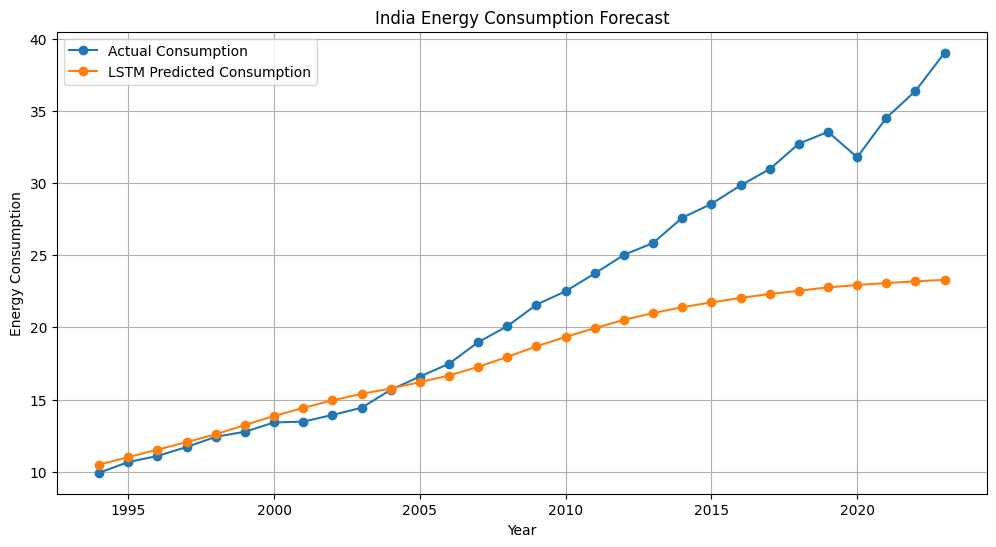

,Year,Actual,Predicted
0,1994,9.93,10.491673
1,1995,10.67,11.011854
2,1996,11.09,11.530947
3,1997,11.71,12.050514
4,1998,12.42,12.593635
5,1999,12.77,13.237277
6,2000,13.41,13.860425
7,2001,13.47,14.419078
8,2002,13.93,14.941524
9,2003,14.43,15.393290


In [ ]:
import matplotlib.pyplot as plt

test_years = test_df["Year"].to_numpy()

results = pd.DataFrame({
    "Year": test_years,
    "Actual": y_test_actual,
    "Predicted": y_pred_actual
})

plt.figure(figsize=(12, 6))

plt.plot(
    results["Year"], results["Actual"],
    marker="o", label="Actual Consumption"
)

plt.plot(
    results["Year"], results["Predicted"],
    marker="o", label="LSTM Predicted Consumption"
)

plt.title("India Energy Consumption Forecast")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)
plt.show()

display(results.head(10))

In [ ]:
latest_five = country_df[
    ["Energy_Consumption"]
].tail(5).to_numpy()

latest_five_scaled = scaler.transform(latest_five)

next_input = latest_five_scaled.reshape(1, 5, 1)

next_scaled = model.predict(next_input, verbose=0)

next_prediction = scaler.inverse_transform(
    next_scaled
)[0, 0]

next_year = int(country_df["Year"].max()) + 1

print("Country:", country_name)
print("Latest available year:", int(country_df["Year"].max()))
print("Forecast year:", next_year)
print(f"Predicted energy consumption: {next_prediction:.2f}")

Country: India
Latest available year: 2023
Forecast year: 2024
Predicted energy consumption: 23.34


In [ ]:
results.to_csv("india_energy_predictions.csv", index=False)

from google.colab import files
files.download("india_energy_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model.save("world_energy_lstm.keras")
files.download("world_energy_lstm.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import gradio as gr
import matplotlib.pyplot as plt

def show_forecast():
    summary = (
        f"Country: {country_name}\n"
        f"Training records: {len(train_df)}\n"
        f"Testing records: {len(test_df)}\n"
        f"MAE: {mae:.4f}\n"
        f"RMSE: {rmse:.4f}\n"
        f"Forecast year: {next_year}\n"
        f"Predicted consumption: {next_prediction:.2f}"
    )

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(
        results["Year"], results["Actual"],
        marker="o", label="Actual"
    )
    ax.plot(
        results["Year"], results["Predicted"],
        marker="o", label="Predicted"
    )

    ax.set_title(f"{country_name} Energy Consumption Forecast")
    ax.set_xlabel("Year")
    ax.set_ylabel("Energy Consumption")
    ax.legend()
    ax.grid(True)
    fig.tight_layout()

    return summary, fig

with gr.Blocks(title="World Energy Forecasting") as demo:
    gr.Markdown("# World Energy Consumption Forecasting")
    gr.Markdown("LSTM-based Energy Prediction Dashboard")

    output_text = gr.Textbox(label="Forecast Results", lines=7)
    output_plot = gr.Plot(label="Actual vs Predicted")

    button = gr.Button("Generate Forecast")
    button.click(
        fn=show_forecast,
        inputs=[],
        outputs=[output_text, output_plot]
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a610fc10b73c2c9527.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

tf.keras.utils.set_random_seed(42)

# Split training sequences into training and validation chronologically
val_size = max(1, int(len(X_train) * 0.2))

X_fit = X_train[:-val_size]
y_fit = y_train[:-val_size]

X_val = X_train[-val_size:]
y_val = y_train[-val_size:]

candidates = []
comparison = []

for units in [16, 32, 64]:
    model_candidate = Sequential([
        Input(shape=(5, 1)),
        LSTM(units),
        Dense(16, activation="relu"),
        Dense(1)
    ])

    model_candidate.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    stop = EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    )

    model_candidate.fit(
        X_fit,
        y_fit,
        validation_data=(X_val, y_val),
        epochs=150,
        batch_size=4,
        shuffle=False,
        callbacks=[stop],
        verbose=0
    )

    val_pred = model_candidate.predict(X_val, verbose=0)
    val_pred_actual = scaler.inverse_transform(val_pred).ravel()
    val_actual = scaler.inverse_transform(y_val).ravel()

    val_mae = mean_absolute_error(val_actual, val_pred_actual)
    val_rmse = np.sqrt(mean_squared_error(val_actual, val_pred_actual))

    candidates.append(model_candidate)
    comparison.append({
        "LSTM Units": units,
        "Validation MAE": val_mae,
        "Validation RMSE": val_rmse
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

best_index = comparison_df["Validation MAE"].idxmin()
model = candidates[best_index]

print("Selected LSTM units:",
      int(comparison_df.loc[best_index, "LSTM Units"]))
print("Best model selected using validation MAE.")

,LSTM Units,Validation MAE,Validation RMSE
0,16,0.237231,0.280358
1,32,0.278175,0.313214
2,64,0.370766,0.406759


Selected LSTM units: 16
Best model selected using validation MAE.


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Predict on the test dataset
pred_scaled = model.predict(X_test, verbose=0)

# Convert values back to original energy units
y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

y_pred_actual = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).ravel()

# Calculate final test metrics
mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

print("Improved LSTM Model - India")
print(f"Test MAE: {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")

Improved LSTM Model - India
Test MAE: 5.9991
Test RMSE: 8.5429


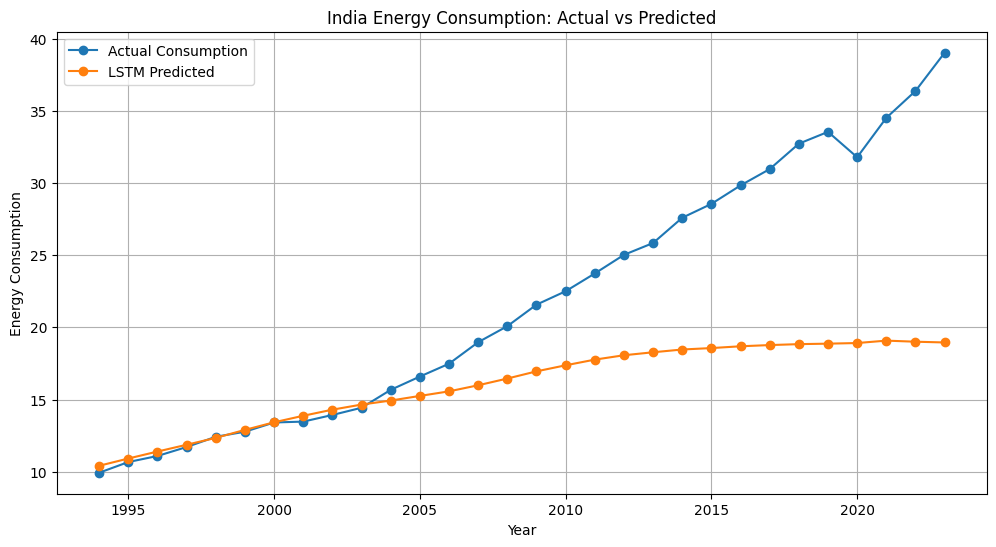

,Year,Actual,Predicted
0,1994,9.93,10.411503
1,1995,10.67,10.914381
2,1996,11.09,11.396627
3,1997,11.71,11.867519
4,1998,12.42,12.343089
5,1999,12.77,12.896964
6,2000,13.41,13.423349
7,2001,13.47,13.874593
8,2002,13.93,14.297488
9,2003,14.43,14.651121


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

results = pd.DataFrame({
    "Year": test_df["Year"].to_numpy(),
    "Actual": y_test_actual,
    "Predicted": y_pred_actual
})

plt.figure(figsize=(12, 6))

plt.plot(
    results["Year"],
    results["Actual"],
    marker="o",
    label="Actual Consumption"
)

plt.plot(
    results["Year"],
    results["Predicted"],
    marker="o",
    label="LSTM Predicted"
)

plt.title("India Energy Consumption: Actual vs Predicted")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)
plt.show()

display(results.head(10))

In [ ]:
# Get the latest 5 years of energy consumption
latest_five = country_df[
    ["Energy_Consumption"]
].tail(5).to_numpy()

# Normalize using the existing scaler
latest_five_scaled = scaler.transform(latest_five)

# Reshape for LSTM input: (samples, years, features)
next_input = latest_five_scaled.reshape(1, 5, 1)

# Predict next year
next_scaled = model.predict(next_input, verbose=0)

# Convert back to original scale
next_prediction = scaler.inverse_transform(
    next_scaled.reshape(-1, 1)
)[0, 0]

next_year = int(country_df["Year"].max()) + 1

print("Country:", country_name)
print("Last available year:", int(country_df["Year"].max()))
print("Forecast year:", next_year)
print(f"Predicted energy consumption: {next_prediction:.2f}")

Country: India
Last available year: 2023
Forecast year: 2024
Predicted energy consumption: 18.82


In [ ]:
import gradio as gr
import matplotlib.pyplot as plt
import pandas as pd

def final_dashboard():
    summary = (
        f"Country: {country_name}\n"
        f"Training records: {len(train_df)}\n"
        f"Testing records: {len(test_df)}\n"
        f"Model: Improved LSTM ({int(comparison_df.loc[best_index, 'LSTM Units'])} units)\n"
        f"Test MAE: {mae:.4f}\n"
        f"Test RMSE: {rmse:.4f}\n"
        f"Forecast year: {next_year}\n"
        f"Predicted consumption: {next_prediction:.2f}"
    )

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(
        results["Year"], results["Actual"],
        marker="o", label="Actual"
    )
    ax.plot(
        results["Year"], results["Predicted"],
        marker="o", label="Predicted"
    )
    ax.set_title(f"{country_name} Energy Consumption Forecast")
    ax.set_xlabel("Year")
    ax.set_ylabel("Energy Consumption")
    ax.legend()
    ax.grid(True)
    fig.tight_layout()

    return summary, fig, results

with gr.Blocks(title="World Energy Forecasting Product") as final_demo:
    gr.Markdown("# 🌍 World Energy Consumption Forecasting")
    gr.Markdown("### LSTM-based energy consumption prediction")

    summary_output = gr.Textbox(
        label="Forecast Results",
        lines=8
    )

    graph_output = gr.Plot(label="Actual vs Predicted")
    table_output = gr.Dataframe(label="Testing Predictions")

    forecast_button = gr.Button("Generate Forecast")
    forecast_button.click(
        fn=final_dashboard,
        inputs=[],
        outputs=[summary_output, graph_output, table_output]
    )

final_demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://52746de63d3d21d351.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from google.colab import files
import os
import zipfile

# Save prediction results
results.to_csv("india_energy_predictions.csv", index=False)

# Save the selected LSTM model
model.save("world_energy_lstm.keras")

print("Prediction CSV and trained model saved!")

Prediction CSV and trained model saved!


In [ ]:
files.download("india_energy_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("world_energy_lstm.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Train the final forecasting model on all available historical data
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Use all available India records for the final forecasting model
full_values = country_df[["Energy_Consumption"]].to_numpy(dtype=float)

final_scaler = MinMaxScaler()
full_scaled = final_scaler.fit_transform(full_values)

# Create 5-year input sequences
X_full, y_full = create_sequences(full_scaled, window_size)

# Use the selected number of LSTM units
best_units = int(comparison_df.loc[best_index, "LSTM Units"])

tf.keras.utils.set_random_seed(42)

final_model = Sequential([
    Input(shape=(5, 1)),
    LSTM(best_units),
    Dense(16, activation="relu"),
    Dense(1)
])

final_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

final_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

final_model.fit(
    X_full,
    y_full,
    epochs=150,
    batch_size=4,
    validation_split=0.2,
    shuffle=False,
    callbacks=[final_stop],
    verbose=1
)

# Forecast the year after the latest year
latest_five = full_scaled[-5:].reshape(1, 5, 1)
forecast_scaled = final_model.predict(latest_five, verbose=0)

final_forecast = final_scaler.inverse_transform(
    forecast_scaled
)[0, 0]

forecast_year = int(country_df["Year"].max()) + 1

print("Final model trained successfully!")
print("Selected LSTM units:", best_units)
print("Forecast year:", forecast_year)
print(f"Forecast energy consumption: {final_forecast:.2f}")


Epoch 1/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - loss: 0.0671 - mae: 0.2008 - val_loss: 0.6144 - val_mae: 0.7769
Epoch 2/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0495 - mae: 0.1619 - val_loss: 0.5089 - val_mae: 0.7064
Epoch 3/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0350 - mae: 0.1358 - val_loss: 0.4103 - val_mae: 0.6335
Epoch 4/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0250 - mae: 0.1196 - val_loss: 0.3271 - val_mae: 0.5647
Epoch 5/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0186 - mae: 0.1074 - val_loss: 0.2546 - val_mae: 0.4974
Epoch 6/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0153 - mae: 0.1013 - val_loss: 0.2006 - val_mae: 0.4407
Epoch 7/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0132 - mae: 0.0964 - val_loss: 0.1609 - val_mae: 0.3940
Epoch 8/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0114 - mae: 0.0903 - val_loss: 0.1309 - val_mae: 0.3549
Epoch 9/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - lo

In [ ]:

import gradio as gr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Prepare country options
country_options = sorted(
    country_df["Country"].dropna().unique().tolist()
)

def forecast_country(selected_country):
    data = energy_df[
        energy_df["Country"].astype(str).str.strip().str.lower()
        == selected_country.strip().lower()
    ].copy()

    data["Year"] = pd.to_numeric(data["Year"], errors="coerce")
    data["Energy_Consumption"] = pd.to_numeric(
        data["Energy_Consumption"], errors="coerce"
    )

    data = (
        data.dropna(subset=["Year", "Energy_Consumption"])
        .sort_values("Year")
        .drop_duplicates(subset=["Year"], keep="last")
        .reset_index(drop=True)
    )

    if len(data) < 15:
        return "Not enough yearly records for forecasting.", None, None

    values = data[["Energy_Consumption"]].to_numpy(dtype=float)

    # Chronological 50:50 evaluation split
    split = len(values) // 2
    train_values = values[:split]
    test_values = values[split:]

    if len(train_values) < 7 or len(test_values) < 1:
        return "Not enough records for the selected split.", None, None

    scaler = MinMaxScaler()
    train_scaled = scaler.fit_transform(train_values)
    test_scaled = scaler.transform(test_values)

    window = 5

    def sequences(arr):
        X, y = [], []
        for i in range(window, len(arr)):
            X.append(arr[i-window:i])
            y.append(arr[i])
        return np.array(X), np.array(y)

    X_train, y_train = sequences(train_scaled)

    test_context = np.concatenate(
        [train_scaled[-window:], test_scaled], axis=0
    )
    X_test, y_test = sequences(test_context)

    if len(X_train) < 2 or len(X_test) == 0:
        return "Not enough sequences to train and evaluate.", None, None

    tf.keras.utils.set_random_seed(42)

    candidate = Sequential([
        Input(shape=(window, 1)),
        LSTM(16),
        Dense(16, activation="relu"),
        Dense(1)
    ])

    candidate.compile(optimizer="adam", loss="mse", metrics=["mae"])

    stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    candidate.fit(
        X_train, y_train,
        epochs=100,
        batch_size=4,
        validation_split=0.2,
        shuffle=False,
        callbacks=[stop],
        verbose=0
    )

    predictions_scaled = candidate.predict(X_test, verbose=0)

    actual = scaler.inverse_transform(y_test).ravel()
    predicted = scaler.inverse_transform(predictions_scaled).ravel()

    mae_value = mean_absolute_error(actual, predicted)
    rmse_value = np.sqrt(mean_squared_error(actual, predicted))

    # Retrain a forecasting model on all available history
    full_scaler = MinMaxScaler()
    full_scaled = full_scaler.fit_transform(values)
    X_full, y_full = sequences(full_scaled)

    final = Sequential([
        Input(shape=(window, 1)),
        LSTM(16),
        Dense(16, activation="relu"),
        Dense(1)
    ])
    final.compile(optimizer="adam", loss="mse")

    final.fit(
        X_full, y_full,
        epochs=100,
        batch_size=4,
        shuffle=False,
        verbose=0
    )

    next_input = full_scaled[-window:].reshape(1, window, 1)
    next_scaled = final.predict(next_input, verbose=0)
    next_value = full_scaler.inverse_transform(next_scaled)[0, 0]
    next_year = int(data["Year"].max()) + 1

    result = pd.DataFrame({
        "Year": data["Year"].iloc[split:].astype(int).to_numpy(),
        "Actual": actual,
        "Predicted": predicted
    })

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(result["Year"], result["Actual"], marker="o", label="Actual")
    ax.plot(result["Year"], result["Predicted"], marker="o", label="Predicted")
    ax.set_title(f"{selected_country} Energy Consumption")
    ax.set_xlabel("Year")
    ax.set_ylabel("Energy Consumption")
    ax.grid(True)
    ax.legend()
    fig.tight_layout()

    summary = (
        f"Country: {selected_country}\n"
        f"Available records: {len(data)}\n"
        f"Training records: {len(train_values)}\n"
        f"Testing records: {len(test_values)}\n"
        f"Test MAE: {mae_value:.4f}\n"
        f"Test RMSE: {rmse_value:.4f}\n"
        f"Forecast year: {next_year}\n"
        f"Predicted consumption: {next_value:.2f}"
    )

    return summary, fig, result

with gr.Blocks(title="World Energy Forecasting") as product_app:
    gr.Markdown("# World Energy Consumption Forecasting")
    gr.Markdown("Select a country to view its energy forecast.")

    country_dropdown = gr.Dropdown(
        choices=country_options,
        value="India" if "India" in country_options else country_options[0],
        label="Select Country"
    )

    forecast_button = gr.Button("Generate Forecast")
    summary_box = gr.Textbox(label="Forecast Summary", lines=8)
    chart_box = gr.Plot(label="Actual vs Predicted")
    table_box = gr.Dataframe(label="Testing Predictions")

    forecast_button.click(
        forecast_country,
        inputs=[country_dropdown],
        outputs=[summary_box, chart_box, table_box]
    )

product_app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a7008cc46151e35f8e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

import gradio as gr
import pandas as pd
import numpy as np
import os

def download_predictions(selected_country):
    data = energy_df[
        energy_df["Country"].astype(str).str.strip().str.lower()
        == selected_country.strip().lower()
    ].copy()

    data["Year"] = pd.to_numeric(data["Year"], errors="coerce")
    data["Energy_Consumption"] = pd.to_numeric(
        data["Energy_Consumption"], errors="coerce"
    )

    data = (
        data.dropna(subset=["Year", "Energy_Consumption"])
        .sort_values("Year")
        .drop_duplicates(subset=["Year"], keep="last")
        .reset_index(drop=True)
    )

    if len(data) < 15:
        raise gr.Error("Not enough yearly records for this country.")

    values = data[["Energy_Consumption"]].to_numpy(dtype=float)
    split = len(values) // 2

    scaler_download = MinMaxScaler()
    train_scaled = scaler_download.fit_transform(values[:split])
    test_scaled = scaler_download.transform(values[split:])

    window = 5
    test_context = np.concatenate(
        [train_scaled[-window:], test_scaled], axis=0
    )

    X_test_download, y_test_download = sequences(test_context)

    tf.keras.utils.set_random_seed(42)

    download_model = Sequential([
        Input(shape=(window, 1)),
        LSTM(16),
        Dense(16, activation="relu"),
        Dense(1)
    ])

    download_model.compile(optimizer="adam", loss="mse")
    X_train_download, y_train_download = sequences(train_scaled)

    download_model.fit(
        X_train_download,
        y_train_download,
        epochs=100,
        batch_size=4,
        shuffle=False,
        verbose=0
    )

    predictions_scaled = download_model.predict(
        X_test_download, verbose=0
    )

    actual = scaler_download.inverse_transform(
        y_test_download
    ).ravel()

    predicted = scaler_download.inverse_transform(
        predictions_scaled
    ).ravel()

    output = pd.DataFrame({
        "Year": data["Year"].iloc[split:].astype(int).to_numpy(),
        "Actual": actual,
        "Predicted": predicted
    })

    filename = f"{selected_country.lower().replace(' ', '_')}_energy_predictions.csv"
    output.to_csv(filename, index=False)
    return filename

with gr.Blocks(title="Energy Prediction Downloads") as download_app:
    gr.Markdown("# Download Energy Forecast Results")
    download_country = gr.Dropdown(
        choices=country_options,
        value="India" if "India" in country_options else country_options[0],
        label="Select Country"
    )
    download_button = gr.Button("Prepare CSV")
    csv_file = gr.File(label="Download Predictions CSV")

    download_button.click(
        download_predictions,
        inputs=download_country,
        outputs=csv_file
    )

download_app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2cbe2916f974477dea.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from google.colab import files

results.to_csv("energy_predictions.csv", index=False)
files.download("energy_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Compare two methods on the same test years
comparison_results = results.copy()

# Baseline: predict this year using the previous year's actual value
comparison_results["Baseline"] = (
    comparison_results["Actual"].shift(1)
)

# First test year-ku previous year's actual value use pannuvom
first_test_year = int(comparison_results["Year"].iloc[0])
previous_year_actual = country_df.loc[
    country_df["Year"] == first_test_year - 1,
    "Energy_Consumption"
]

if not previous_year_actual.empty:
    comparison_results.loc[
        comparison_results.index[0], "Baseline"
    ] = previous_year_actual.iloc[-1]

comparison_results = comparison_results.dropna(
    subset=["Actual", "Predicted", "Baseline"]
)

lstm_mae = mean_absolute_error(
    comparison_results["Actual"],
    comparison_results["Predicted"]
)
lstm_rmse = np.sqrt(mean_squared_error(
    comparison_results["Actual"],
    comparison_results["Predicted"]
))

baseline_mae = mean_absolute_error(
    comparison_results["Actual"],
    comparison_results["Baseline"]
)
baseline_rmse = np.sqrt(mean_squared_error(
    comparison_results["Actual"],
    comparison_results["Baseline"]
))

comparison_table = pd.DataFrame({
    "Model": ["Previous-Year Baseline", "LSTM"],
    "MAE": [baseline_mae, lstm_mae],
    "RMSE": [baseline_rmse, lstm_rmse]
})

display(comparison_table)


,Model,MAE,RMSE
0,Previous-Year Baseline,1.104000,1.266683
1,LSTM,5.999136,8.542933


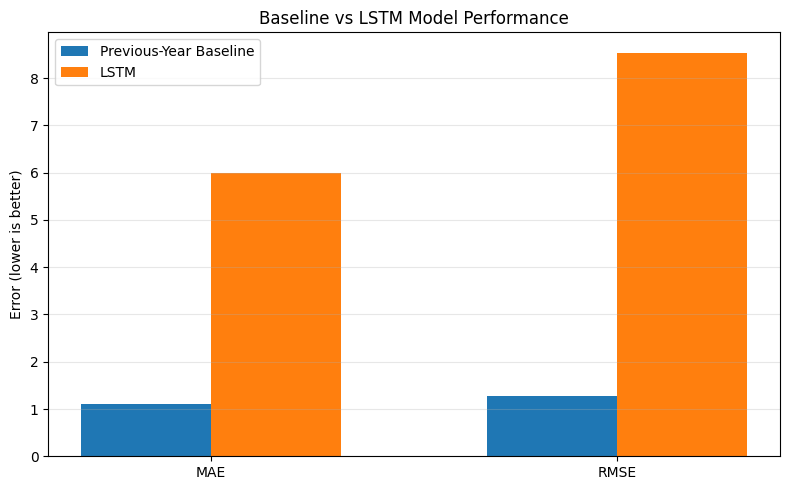

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["MAE", "RMSE"]
baseline_scores = [baseline_mae, baseline_rmse]
lstm_scores = [lstm_mae, lstm_rmse]

x = np.arange(len(metrics))
width = 0.32

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(x - width / 2, baseline_scores, width,
       label="Previous-Year Baseline")
ax.bar(x + width / 2, lstm_scores, width,
       label="LSTM")

ax.set_title("Baseline vs LSTM Model Performance")
ax.set_ylabel("Error (lower is better)")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

import gradio as gr
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

def final_product(country):
    # Reuse the country forecasting function already created
    summary, forecast_fig, prediction_table = forecast_country(country)

    if prediction_table is None:
        raise gr.Error(str(summary))

    # Calculate previous-year baseline on the same prediction years
    data = energy_df[
        energy_df["Country"].astype(str).str.strip().str.lower()
        == country.strip().lower()
    ].copy()

    data["Year"] = pd.to_numeric(data["Year"], errors="coerce")
    data["Energy_Consumption"] = pd.to_numeric(
        data["Energy_Consumption"], errors="coerce"
    )

    data = (
        data.dropna(subset=["Year", "Energy_Consumption"])
        .sort_values("Year")
        .drop_duplicates(subset=["Year"], keep="last")
        .reset_index(drop=True)
    )

    split = len(data) // 2
    test_years = data["Year"].iloc[split:].astype(int).to_numpy()
    actual = prediction_table["Actual"].to_numpy()
    predicted = prediction_table["Predicted"].to_numpy()

    baseline_values = []
    for year in test_years:
        previous = data.loc[
            data["Year"] == year - 1, "Energy_Consumption"
        ]
        baseline_values.append(
            float(previous.iloc[-1]) if not previous.empty else np.nan
        )

    baseline_values = np.asarray(baseline_values, dtype=float)
    valid = np.isfinite(baseline_values)

    baseline_mae_value = np.mean(
        np.abs(actual[valid] - baseline_values[valid])
    )
    baseline_rmse_value = np.sqrt(np.mean(
        (actual[valid] - baseline_values[valid]) ** 2
    ))

    comparison = pd.DataFrame({
        "Model": ["Previous-Year Baseline", "LSTM"],
        "MAE": [
            baseline_mae_value,
            np.mean(np.abs(actual - predicted))
        ],
        "RMSE": [
            baseline_rmse_value,
            np.sqrt(np.mean((actual - predicted) ** 2))
        ]
    })

    # Combine predictions and baseline for download
    export_table = prediction_table.copy()
    export_table["Baseline"] = baseline_values

    csv_path = f"{country.lower().replace(' ', '_')}_forecast.csv"
    export_table.to_csv(csv_path, index=False)

    return summary, forecast_fig, prediction_table, comparison, csv_path

country_choices = sorted(
    energy_df["Country"].dropna().astype(str).unique().tolist()
)

with gr.Blocks(title="World Energy Forecasting Product") as complete_app:
    gr.Markdown("# 🌍 World Energy Consumption Forecasting")
    gr.Markdown(
        "Explore historical energy consumption and compare LSTM forecasts "
        "with a simple previous-year baseline."
    )

    country_input = gr.Dropdown(
        choices=country_choices,
        value="India" if "India" in country_choices else country_choices[0],
        label="Select Country"
    )

    run_button = gr.Button("Generate Forecast", variant="primary")
    summary_output = gr.Textbox(label="Forecast Summary", lines=8)
    plot_output = gr.Plot(label="Actual vs Predicted")
    table_output = gr.Dataframe(label="Testing Predictions")
    comparison_output = gr.Dataframe(label="Baseline vs LSTM")
    csv_output = gr.File(label="Download Forecast CSV")

    run_button.click(
        final_product,
        inputs=[country_input],
        outputs=[
            summary_output,
            plot_output,
            table_output,
            comparison_output,
            csv_output
        ]
    )

complete_app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://96b68ebf995a602753.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
